# 02 — Обучение и выбор рекомендательной модели

## Постановка задачи

Для каждого известного пользователя ранжируем до 10 товаров, которых он ещё не видел в доступной истории. Основной сигнал — неявные события Retailrocket: просмотр (вес 1), добавление в корзину (3), покупка (5). Значения суммируются по паре пользователь–товар в обучающей истории.

Сравниваем Global Popularity, Recent Popularity, ItemKNN и библиотечную ALS из `implicit`. Подбор параметров ItemKNN и ALS ограничен хронологической validation-выборкой; финальный test в этом ноутбуке не загружается.

## Почему эти методы

- **Global Popularity** — понятный ориентир, который показывает, насколько задача объясняется популярностью товаров.
- **Recent Popularity** — baseline по предыдущим 14 дням до начала validation; он проверяет временной дрейф спроса, не заглядывая в будущее.
- **ItemKNN** — коллаборативная фильтрация «товар–товар»: похожесть строится по общим пользователям, а профиль пользователя суммирует соседние товары.
- **implicit ALS** — библиотечная факторизация матрицы взаимодействий с confidence-weighted objective. Модель обучается на данных проекта, она не предобученная.

Основная метрика — NDCG@10: она учитывает позиции рекомендаций. Recall@10 и Precision@10 измеряют охват релевантных товаров и точность выдачи, а Coverage@10 — долю каталога, которую модель вообще рекомендует. Уже просмотренные товары исключаются.

## Что реализовано в проекте, а что даёт библиотека

Popularity и ItemKNN — проектные классы в `src/recommendation.py`. ALS используется только из `implicit.als.AlternatingLeastSquares`; адаптер приводит библиотечный интерфейс к общему API проекта. NumPy, Pandas и SciPy используются как вычислительные инструменты; ALS применяется только из пакета `implicit`.

| Модель | Реализация проекта | Используемая библиотека |
|---|---|---|
| Global Popularity | `PopularityRecommender`: суммирует веса событий по товару | Pandas группирует события |
| Recent Popularity | `RecentPopularityRecommender`: учитывает предыдущие 14 дней | Pandas фильтрует события по времени |
| ItemKNN | `ItemKNNRecommender`: строит item-item сходство и оценивает профиль пользователя | SciPy выполняет операции над разреженными матрицами |
| implicit ALS | `ImplicitLibraryALSRecommender` — адаптер к `implicit.als.AlternatingLeastSquares` | Пакет `implicit` реализует и оптимизирует ALS; веса событий обучаются на train |

Здесь сравниваются не две реализации ALS, а готовая библиотечная ALS с популярностными ориентирами и ItemKNN.

## Хронологический протокол и границы бенчмарка

Порог истории пользователя (не менее пяти событий), когорта до 20 000 пользователей и каталог из 1 500 наиболее популярных товаров определяются только по train. Модели получают события train этой когорты и каталога. Это ограниченный offline-бенчмарк, а не оценка всей аудитории или полного каталога.

Validation-цели фильтруются по тому же каталогу; релевантны новые для пользователя товары с событиями в validation. ItemKNN и ALS выбираются по NDCG@10 только на этой хронологической выборке. Test не читается и не участвует ни в подборе, ни в выборе конфигурации.

In [1]:
from pathlib import Path
import sys
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "outputs" / "figures"
METRICS = ROOT / "outputs" / "metrics"
FIGURES.mkdir(parents=True, exist_ok=True)
METRICS.mkdir(parents=True, exist_ok=True)

from src.recommendation import (
    PopularityRecommender, RecentPopularityRecommender,
    ItemKNNRecommender, ImplicitLibraryALSRecommender,
    build_interaction_data, select_benchmark_users, select_catalog_items,
)
from src.evaluation import evaluate_recommender
from src.model_selection import (
    evaluate_recommender_grid, select_best_validation_configuration,
)
from src.retailrocket import load_processed_events

train = load_processed_events(PROCESSED / "train.csv")
validation = load_processed_events(PROCESSED / "validation.csv")
MIN_HISTORY = 5
MAX_USERS = 20000
MAX_ITEMS = 1500
SEED = 42
K = 10

cohort = select_benchmark_users(train, min_history=MIN_HISTORY,
                                max_users=MAX_USERS, random_state=SEED)
catalog = select_catalog_items(train, max_items=MAX_ITEMS)
train_benchmark = train[
    train.visitorid.isin(cohort) & train.itemid.isin(catalog)
].copy()
validation_benchmark = validation[
    validation.visitorid.isin(cohort) & validation.itemid.isin(catalog)
].copy()
interaction_data = build_interaction_data(
    train_benchmark, user_ids=cohort, item_ids=catalog
)

print("Когорта, выбранная по train: {:,} пользователей; каталог: {:,} товаров.".format(
    len(cohort), len(catalog)))
print("Обучающих событий в бенчмарке: {:,}; ненулевых пар пользователь–товар: {:,}.".format(
    len(train_benchmark), interaction_data.matrix.nnz))
print("Событий validation в когорте и каталоге: {:,}.".format(len(validation_benchmark)))
assert train.event_time.max() < validation.event_time.min()
assert train_benchmark.visitorid.isin(cohort).all()
assert train_benchmark.itemid.isin(catalog).all()

/Users/mariatreseva/opt/anaconda3/lib/python3.9/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/Users/mariatreseva/opt/anaconda3/lib/python3.9/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.4' currently installed).
  from pandas.core import (


Когорта, выбранная по train: 20,000 пользователей; каталог: 1,500 товаров.
Обучающих событий в бенчмарке: 50,447; ненулевых пар пользователь–товар: 24,543.
Событий validation в когорте и каталоге: 1,552.


## Подбор параметров на validation

Для уменьшения стоимости поиска используется компактная сетка: ItemKNN — `neighbors ∈ {25, 50, 100}` и `shrinkage ∈ {0, 10}` (6 комбинаций); implicit ALS — `factors ∈ {32, 64}`, `regularization ∈ {0.05, 0.1}`, `alpha ∈ {10, 20}` (8 комбинаций). Число итераций ALS зафиксировано на 8, seed — 42, чтобы поиск оставался небольшим и воспроизводимым. Для каждой конфигурации модель обучается только на train и оценивается по одной и той же validation-выборке; победитель определяется по NDCG@10.
Сетки и выбор конфигураций задаются здесь; в `src/` остаются общие функции обучения и оценки. NDCG в ноутбуке 02 использует graded relevance (веса событий); в 04 — binary relevance, поэтому их значения напрямую не сравниваем.


In [2]:
itemknn_grid = [
    {"neighbors": neighbors, "shrinkage": shrinkage}
    for neighbors in (25, 50, 100)
    for shrinkage in (0.0, 10.0)
]
als_grid = [
    {
        "factors": factors,
        "regularization": regularization,
        "alpha": alpha,
        "iterations": 8,
        "random_state": SEED,
        "num_threads": 1,
    }
    for factors in (32, 64)
    for regularization in (0.05, 0.1)
    for alpha in (10.0, 20.0)
]



## Эксперимент 1 — ItemKNN

**Гипотеза.** Увеличение соседства с 25 до 50 добавит полезные связи, но 100 соседей может добавить шум. Shrinkage=10 должен ослабить ненадёжное сходство по редким совместным взаимодействиям. Сравниваем полный факторный план при одинаковой истории и пользователях.

/Users/mariatreseva/opt/anaconda3/lib/python3.9/site-packages/scipy/sparse/_index.py:146: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray(i, j, x)


/Users/mariatreseva/opt/anaconda3/lib/python3.9/site-packages/scipy/sparse/_index.py:146: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray(i, j, x)


/Users/mariatreseva/opt/anaconda3/lib/python3.9/site-packages/scipy/sparse/_index.py:146: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray(i, j, x)


/Users/mariatreseva/opt/anaconda3/lib/python3.9/site-packages/scipy/sparse/_index.py:146: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray(i, j, x)


/Users/mariatreseva/opt/anaconda3/lib/python3.9/site-packages/scipy/sparse/_index.py:146: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray(i, j, x)


/Users/mariatreseva/opt/anaconda3/lib/python3.9/site-packages/scipy/sparse/_index.py:146: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray(i, j, x)


,neighbors,shrinkage,ndcg@10,recall@10,precision@10,coverage@10,evaluated_users,catalog_items,recommended_unique_items,model,fit_seconds
0,25,0.0,0.058268,0.087490,0.014050,0.488667,242,1500,733,ItemKNN,0.043458
1,25,10.0,0.063279,0.096444,0.016942,0.482000,242,1500,723,ItemKNN,0.041107
2,50,0.0,0.062268,0.099887,0.015702,0.478000,242,1500,717,ItemKNN,0.043188
3,50,10.0,0.065500,0.103398,0.017769,0.468000,242,1500,702,ItemKNN,0.042005
4,100,0.0,0.060806,0.096957,0.015702,0.476667,242,1500,715,ItemKNN,0.045862
5,100,10.0,0.064828,0.100882,0.017355,0.465333,242,1500,698,ItemKNN,0.045258


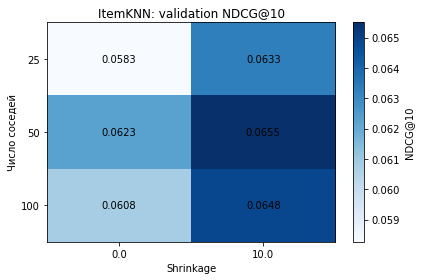

In [3]:
itemknn_tuning = evaluate_recommender_grid(
    train_benchmark, validation_benchmark, cohort, catalog, itemknn_grid,
    lambda data, params: ItemKNNRecommender(**params).fit(data),
    model_name="ItemKNN", k=K,
)

itemknn_tuning.to_csv(METRICS / "itemknn_tuning_validation.csv", index=False)
display(itemknn_tuning.round(6))
knn_surface = itemknn_tuning.pivot(index="neighbors", columns="shrinkage", values="ndcg@10")
fig, ax = plt.subplots(figsize=(6, 4))
image = ax.imshow(knn_surface.values, aspect="auto", cmap="Blues")
ax.set_xticks(np.arange(len(knn_surface.columns)), labels=[str(value) for value in knn_surface.columns])
ax.set_yticks(np.arange(len(knn_surface.index)), labels=[str(value) for value in knn_surface.index])
ax.set(xlabel="Shrinkage", ylabel="Число соседей", title="ItemKNN: validation NDCG@10")
for row in range(knn_surface.shape[0]):
    for column in range(knn_surface.shape[1]):
        ax.text(column, row, "{:.4f}".format(knn_surface.iloc[row, column]),
                ha="center", va="center", color="black")
fig.colorbar(image, ax=ax, label="NDCG@10")
fig.tight_layout()
fig.savefig(FIGURES / "itemknn_tuning_validation.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)



**Вывод по сохранённому прогону.** Shrinkage=10 повышает NDCG@10 при 25, 50 и 100 соседях соответственно на 0.00501, 0.00323 и 0.00402. Это согласуется с гипотезой о шуме редких связей, хотя не доказывает её механизм. При shrinkage=10 переход 25→50 даёт 0.06328→0.06550, а 50→100 снижает качество до 0.06483. Разрыв двух лучших вариантов всего 0.00067 (около 1%); утверждать устойчивое превосходство 50 соседей пока нельзя. Coverage при этом снижается с 0.482 до 0.468 и 0.465: качество растёт без расширения покрытия. Числа относятся к сохранённому прогону; при изменении данных вывод нужно пересмотреть.

## Эксперимент 2 — ALS

**Гипотеза.** 64 фактора вместо 32 дадут более выразительные профили. Увеличение regularization может сдержать переобучение, а alpha усилит доверие к наблюдавшимся взаимодействиям; на разреженной истории слишком сильное доверие может ухудшить ранжирование. Проверяем эффекты при фиксированных остальных параметрах, а не только средние по сетке. Итерации=8 и seed=42 фиксированы: сходимость и устойчивость к инициализации здесь не исследуются.

,factors,regularization,alpha,iterations,random_state,num_threads,ndcg@10,recall@10,precision@10,coverage@10,evaluated_users,catalog_items,recommended_unique_items,model,fit_seconds
0,32,0.05,10.0,8,42,1,0.070146,0.106398,0.019008,0.417333,242,1500,626,implicit ALS,0.254975
1,32,0.05,20.0,8,42,1,0.070116,0.109696,0.019008,0.454000,242,1500,681,implicit ALS,0.229354
2,32,0.10,10.0,8,42,1,0.071792,0.108464,0.019421,0.420667,242,1500,631,implicit ALS,0.229106
3,32,0.10,20.0,8,42,1,0.069161,0.105498,0.017769,0.451333,242,1500,677,implicit ALS,0.229959
4,64,0.05,10.0,8,42,1,0.076494,0.124160,0.020661,0.520667,242,1500,781,implicit ALS,0.470035
5,64,0.05,20.0,8,42,1,0.074295,0.129508,0.021488,0.535333,242,1500,803,implicit ALS,0.468693
6,64,0.10,10.0,8,42,1,0.075975,0.123466,0.020248,0.516667,242,1500,775,implicit ALS,0.471459
7,64,0.10,20.0,8,42,1,0.074006,0.127997,0.020661,0.537333,242,1500,806,implicit ALS,0.474432


/var/folders/lz/_pckzh2s5kqft1jgsbfqwvwm0000gn/T/ipykernel_44454/1426213435.py:24: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


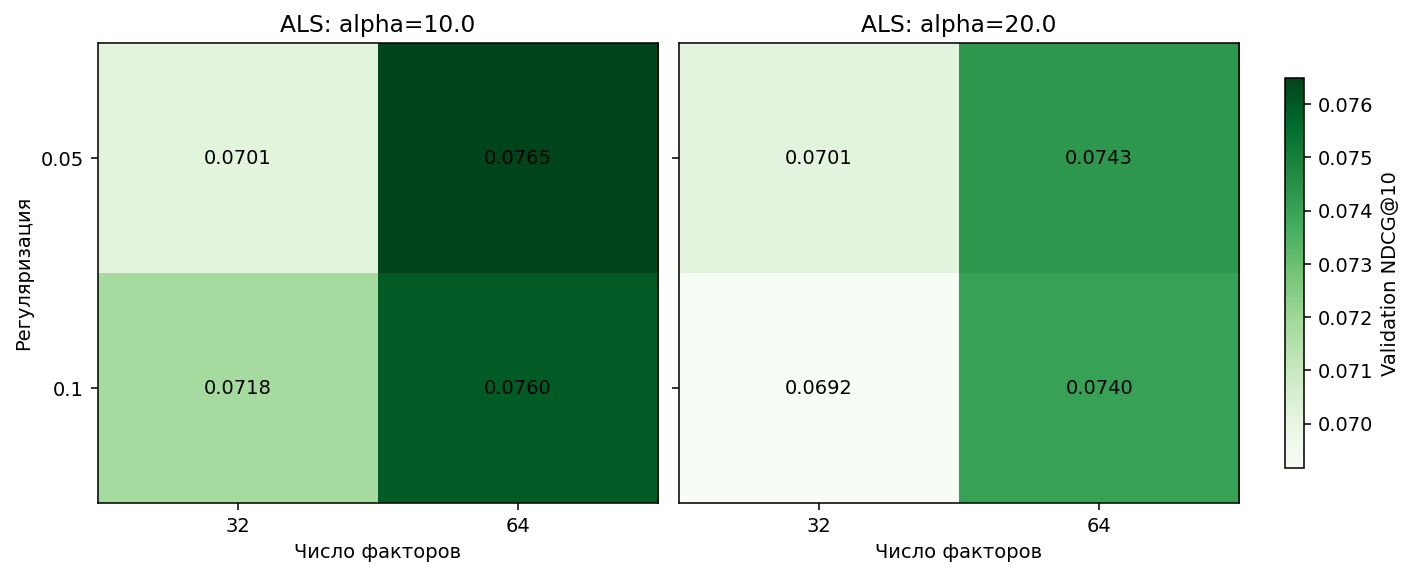

In [4]:
als_tuning = evaluate_recommender_grid(
    train_benchmark, validation_benchmark, cohort, catalog, als_grid,
    lambda data, params: ImplicitLibraryALSRecommender(**params).fit(data),
    model_name="implicit ALS", k=K,
)

als_tuning.to_csv(METRICS / "implicit_als_tuning_validation.csv", index=False)
display(als_tuning.round(6))
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True, constrained_layout=True)
for axis, alpha in zip(axes, sorted(als_tuning["alpha"].unique())):
    surface = als_tuning[als_tuning["alpha"] == alpha].pivot(
        index="regularization", columns="factors", values="ndcg@10"
    )
    image = axis.imshow(surface.values, aspect="auto", cmap="Greens",
                        vmin=als_tuning["ndcg@10"].min(),
                        vmax=als_tuning["ndcg@10"].max())
    axis.set_xticks(np.arange(len(surface.columns)), labels=[str(value) for value in surface.columns])
    axis.set_yticks(np.arange(len(surface.index)), labels=[str(value) for value in surface.index])
    axis.set(xlabel="Число факторов", title="ALS: alpha={}".format(alpha))
    for row in range(surface.shape[0]):
        for column in range(surface.shape[1]):
            axis.text(column, row, "{:.4f}".format(surface.iloc[row, column]),
                      ha="center", va="center", color="black")
axes[0].set_ylabel("Регуляризация")
fig.colorbar(image, ax=axes, label="Validation NDCG@10", shrink=0.85, pad=0.04)
fig.savefig(FIGURES / "implicit_als_tuning_validation.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)



**Вывод по сохранённому прогону.** Во всех четырёх сопоставимых парах 64 фактора лучше 32: прирост NDCG@10 от 0.00418 до 0.00587. Alpha 10→20 снижает NDCG во всех четырёх парах (от 0.00003 до 0.00263), хотя при 64 факторах Recall растёт: нахождение большего числа целей не означает лучшие позиции. Regularization 0.05→0.1 помогает только при factors=32, alpha=10 (+0.00165); в остальных случаях эффект отрицательный. Следовательно, универсального преимущества усиленной регуляризации нет. Лучшая точка — 64 / 0.05 / 10, NDCG=0.07649; при regularization=0.1 — 0.07597, разница всего 0.00052. Факторы влияют заметнее этого локального выбора регуляризации, но один seed и один временной интервал не позволяют объявить параметры универсальными.

## Эксперимент 3 — персонализация против популярности

**Гипотеза.** ItemKNN и ALS используют индивидуальную историю и превзойдут оба popularity baseline по NDCG@10. Проверим также цену улучшения по времени и Coverage. Конфигурации фиксируем по validation; эта же выборка использована при поиске, поэтому сравнение оптимистично и требует независимого test в ноутбуке 03.

In [5]:
itemknn_tuning.to_csv(METRICS / "itemknn_tuning_validation.csv", index=False)
als_tuning.to_csv(METRICS / "implicit_als_tuning_validation.csv", index=False)

best_itemknn = select_best_validation_configuration(itemknn_tuning)
best_als = select_best_validation_configuration(als_tuning)
itemknn_params = {
    "neighbors": int(best_itemknn["neighbors"]),
    "shrinkage": float(best_itemknn["shrinkage"]),
}
als_params = {
    "factors": int(best_als["factors"]),
    "regularization": float(best_als["regularization"]),
    "alpha": float(best_als["alpha"]),
    "iterations": int(best_als["iterations"]),
    "random_state": SEED,
    "num_threads": 1,
}
selected_parameters = {
    "selection_metric": "ndcg@10",
    "random_seed": SEED,
    "validation_start": str(validation.event_time.min()),
    "itemknn": {
        "parameters": itemknn_params,
        "validation_ndcg@10": float(best_itemknn["ndcg@10"]),
    },
    "implicit_als": {
        "parameters": als_params,
        "validation_ndcg@10": float(best_als["ndcg@10"]),
    },
}
with (METRICS / "selected_model_params.json").open("w") as file:
    json.dump(selected_parameters, file, indent=2)

display(itemknn_tuning[["neighbors", "shrinkage", "ndcg@10", "recall@10", "fit_seconds"]].round(4))
display(als_tuning[["factors", "regularization", "alpha", "ndcg@10", "recall@10", "fit_seconds"]].round(4))

models = {}
fit_seconds = {}
def fit_timed(name, factory):
    started = time.perf_counter()
    model = factory()
    fit_seconds[name] = time.perf_counter() - started
    models[name] = model
    return model

fit_timed("Global Popularity", lambda: PopularityRecommender().fit(
    train_benchmark, catalog_items=catalog))
fit_timed("Recent Popularity (14d)", lambda: RecentPopularityRecommender().fit(
    train_benchmark, as_of=validation.event_time.min(), lookback_days=14,
    catalog_items=catalog))
fit_timed("ItemKNN", lambda: ItemKNNRecommender(**itemknn_params).fit(interaction_data))
fit_timed("implicit ALS", lambda: ImplicitLibraryALSRecommender(**als_params).fit(interaction_data))
fit_seconds["ItemKNN"] = float(best_itemknn["fit_seconds"])
fit_seconds["implicit ALS"] = float(best_als["fit_seconds"])

validation_summaries = []
validation_per_user = {}
for name, model in models.items():
    summary, per_user, _ = evaluate_recommender(
        model, validation_benchmark, train_benchmark, cohort, catalog, k=K
    )
    summary["model"] = name
    summary["fit_seconds"] = fit_seconds[name]
    if name == "ItemKNN":
        summary.update(itemknn_params)
    elif name == "implicit ALS":
        summary.update(als_params)
    validation_summaries.append(summary)
    validation_per_user[name] = per_user

validation_results = pd.DataFrame(validation_summaries).set_index("model")
validation_results = validation_results.sort_values("ndcg@10", ascending=False)
validation_results.to_csv(METRICS / "model_validation_metrics.csv")
display(validation_results.round(4))

,neighbors,shrinkage,ndcg@10,recall@10,fit_seconds
0,25,0.0,0.0583,0.0875,0.0435
1,25,10.0,0.0633,0.0964,0.0411
2,50,0.0,0.0623,0.0999,0.0432
3,50,10.0,0.0655,0.1034,0.0420
4,100,0.0,0.0608,0.0970,0.0459
5,100,10.0,0.0648,0.1009,0.0453


,factors,regularization,alpha,ndcg@10,recall@10,fit_seconds
0,32,0.05,10.0,0.0701,0.1064,0.2550
1,32,0.05,20.0,0.0701,0.1097,0.2294
2,32,0.10,10.0,0.0718,0.1085,0.2291
3,32,0.10,20.0,0.0692,0.1055,0.2300
4,64,0.05,10.0,0.0765,0.1242,0.4700
5,64,0.05,20.0,0.0743,0.1295,0.4687
6,64,0.10,10.0,0.0760,0.1235,0.4715
7,64,0.10,20.0,0.0740,0.1280,0.4744


/Users/mariatreseva/opt/anaconda3/lib/python3.9/site-packages/scipy/sparse/_index.py:146: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray(i, j, x)


,ndcg@10,recall@10,precision@10,coverage@10,evaluated_users,catalog_items,recommended_unique_items,fit_seconds,neighbors,shrinkage,factors,regularization,alpha,iterations,random_state,num_threads
model,,,,,,,,,,,,,,,,
implicit ALS,0.0765,0.1242,0.0207,0.5207,242,1500,781,0.4700,NaN,NaN,64.0,0.05,10.0,8.0,42.0,1.0
ItemKNN,0.0655,0.1034,0.0178,0.4680,242,1500,702,0.0420,50.0,10.0,NaN,NaN,NaN,NaN,NaN,NaN
Recent Popularity (14d),0.0278,0.0549,0.0136,0.0160,242,1500,24,0.0032,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Global Popularity,0.0235,0.0356,0.0091,0.0160,242,1500,24,0.0066,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


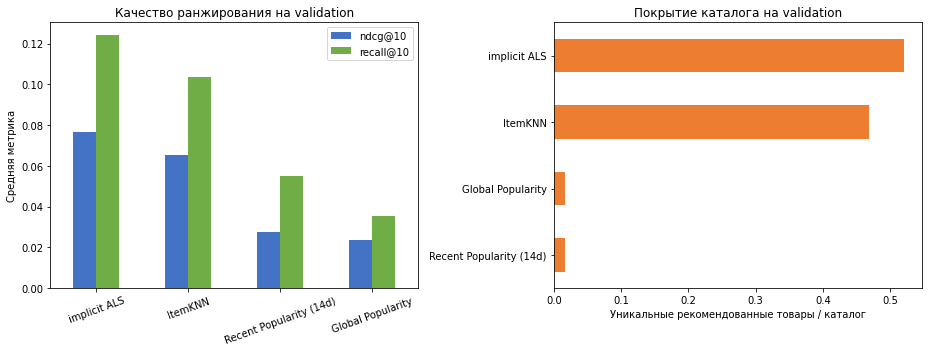

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
validation_results[["ndcg@10", "recall@10"]].plot(kind="bar", ax=axes[0],
    color=["#4472C4", "#70AD47"])
axes[0].set(title="Качество ранжирования на validation", ylabel="Средняя метрика", xlabel="")
axes[0].tick_params(axis="x", rotation=20)
validation_results["coverage@10"].sort_values().plot(kind="barh", ax=axes[1], color="#ED7D31")
axes[1].set(title="Покрытие каталога на validation", xlabel="Уникальные рекомендованные товары / каталог", ylabel="")
fig.tight_layout()
fig.savefig(FIGURES / "model_validation_comparison.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)



**Вывод по сохранённому прогону.** Recent Popularity лучше Global (0.02783 против 0.02352), что согласуется с временным дрейфом спроса. ItemKNN достигает 0.06550, ALS — 0.07649: ALS выше ItemKNN на 0.01099, или 16.8%, и выше Recent Popularity примерно в 2.75 раза. Coverage также выше: ALS 52.1%, ItemKNN 46.8%, popularity 1.6%. ALS обучалась около 0.49 с против 0.04 с у ItemKNN в этом прогоне; время зависит от машины. Это существенный относительный прирост качества, но не доказательство статистической устойчивости: ниже оцениваем неопределённость парной разницы.

,model,reference,users,delta,ci_low,ci_high,relative_delta_pct
0,Global Popularity,ItemKNN,242,-0.041982,-0.068370,-0.016638,-64.095678
1,Recent Popularity (14d),ItemKNN,242,-0.037670,-0.062050,-0.015302,-57.511741
2,implicit ALS,ItemKNN,242,0.010995,-0.007771,0.030474,16.785993


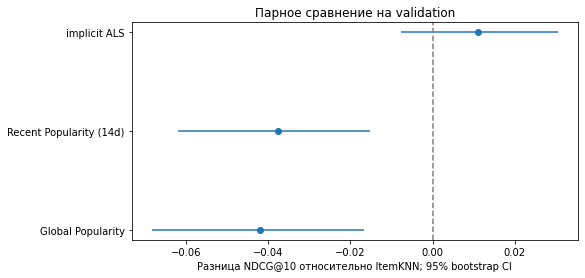

In [7]:
from src.experiment_analysis import paired_metric_comparison
uncertainty = paired_metric_comparison(validation_per_user, reference="ItemKNN", seed=SEED)
display(uncertainty.round(6))
uncertainty.to_csv(METRICS / "model_validation_paired_intervals.csv", index=False)
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(uncertainty["delta"], uncertainty["model"],
            xerr=[uncertainty["delta"] - uncertainty["ci_low"], uncertainty["ci_high"] - uncertainty["delta"]], fmt="o")
ax.axvline(0, color="gray", linestyle="--")
ax.set(xlabel="Разница NDCG@10 относительно ItemKNN; 95% bootstrap CI", title="Парное сравнение на validation")
plt.show()


Интервал, включающий ноль, означает, что знак разницы не установлен этим анализом; интервал выше нуля поддерживает положительный эффект на этой когорте. Bootstrap пересэмплирует пользователей совместно для обеих моделей. Он не учитывает зависимость пользователей через товары, перебор конфигураций и временной дрейф, поэтому validation-интервалы после подбора — диагностические. Практическую ценность оцениваем вместе с абсолютной разницей, покрытием и стоимостью обучения.

**Результат парного анализа выполненного прогона.** Для ALS минус ItemKNN разница +0.01099, 95% интервал [−0.00777; +0.03047]: ноль внутри, поэтому устойчивое преимущество ALS над ItemKNN не установлено. Для обоих popularity baseline интервалы разницы относительно ItemKNN целиком ниже нуля. Данные сильнее поддерживают пользу персонализации по сравнению с популярностью, чем выбор между двумя коллаборативными моделями.
